# 3 Layer Waveguide

This tutorial introduces the use of the slab package for calculating and visualizing fields induced in a simple 3 layer guide by a given input.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from slabguide import Slab, Propagator, real_contour, Plot3D
from scipy.integrate import quad
from scipy.optimize import newton

%matplotlib widget
plt.style.use('dark_background')

## Initialization

Slab waveguide devices are represented using the Slab class.

<!-- An instance of this class is initialized using 4 primary arguments:

- **Ts**: A list of non-dimensional layer thicknesses, which defaults to $[3, 2, 3]$.  These define the thickness of the layers of the guide, from left to right.  The first and last entries define the extent of the outer region of the guide, truncating that which would otherwise extend indefinitely.

- **ns**: A list of refractive indices.  These give the refractive index of each layer of material.  The first and last entry must be equal.  Defaults to $[1.3, 1.5, 1.3]$.

- **wl**: The (dimensional) operating wavelength.  Defaults to $1.8e-6$.

- **scale**: A scaling factor, which defaults to 1e-6.  This non-dimensionalizes all calculations

Remaining arguments define the computational domain's origin and determine plotting parameters. -->

In [2]:
Slab?

Init signature:
Slab(
    Ts=[6, 2, 6],
    ns=[1.3, 1.5, 1.3],
    wl=1.8e-06,
    scale=1e-06,
    xrefs=None,
    no_xs=False,
    Shift=0,
    center=True,
)
Docstring:      A class for calculating the fields of step index slab waveguides.
Init docstring:
Parameters
----------
Ts : list or array, optional
    A list of non-dimensional layer thicknesses.  These define the
    thickness of the layers of the guide, from left to right.  The
    first and last entries define the extent of the outer region of the
    guide, truncating that which would otherwise extend indefinitely.
    The default is [6, 2, 6].
ns : list or array, optional
    A list of refractive indices. These give the refractive index of
    each layer of material. The first and last entry must be equal.
    The default is [1.3, 1.5, 1.3].
wl : float, optional
    The dimensional operating wavelength. The default is 1.8e-6.
scale : float, optional
    Scaling factor which non-dimensionalizes all calculations. The
    


The default instance of the class is a 3 layer step-index guide with higher core index than cladding index.  We call this a Basic 3-Layer guide.  This notebook will explore the use of the class for computing fields in these guides.


In [3]:
A = Slab()


To view the refractive index of the device, call plot_refractive_index:

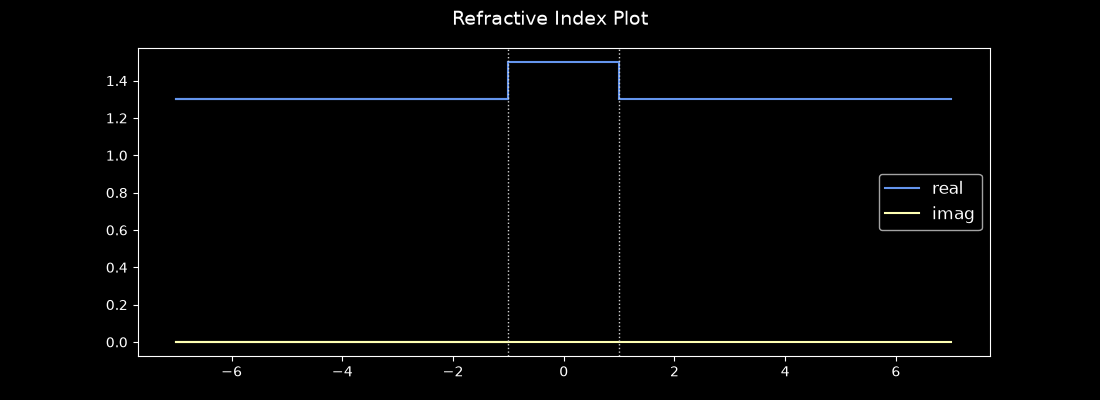

In [4]:
A.plot_refractive_index();


## Input fields

Below we define the field incident on the guide for which the resulting fields inside the structure are to be found.  Along with this, we define the endpoints of an interval [Lx, Rx] (of the transverse axis) outside of which the field is zero.  The wavelength of the field is determined by the operational wavelength of the guide itself.

In [5]:
half_width = 1.75
shift = .25
amplitude = 1.25

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

def quadratic_piecewise2d(x, zs=None, wavenumber=A.K0):
    fx = quadratic_piecewise(x)
    fz = np.exp(1j * wavenumber * zs)
    return np.outer(fz, fx)

f0 = quadratic_piecewise
F0 = quadratic_piecewise2d


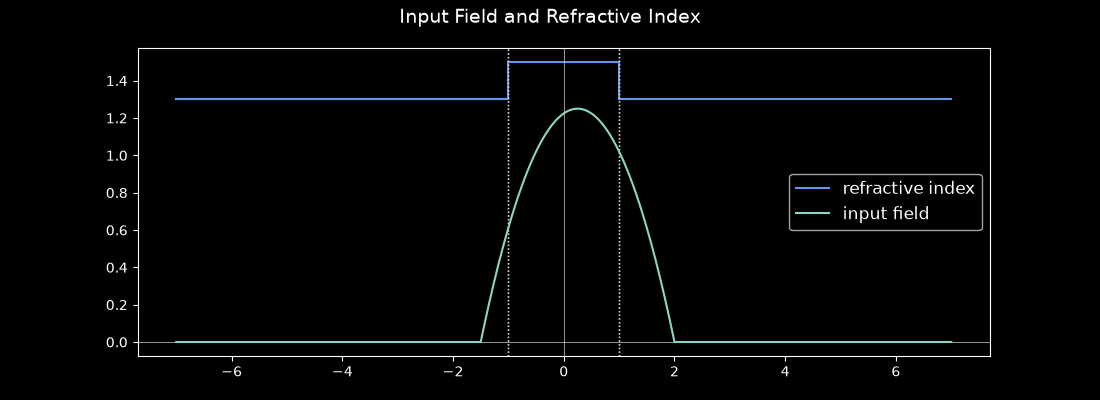

In [9]:
A.plot_refractive_index(part='real', label='refractive index', title="Input Field and Refractive Index");
A.add_1d_plot(F0, label='input field');

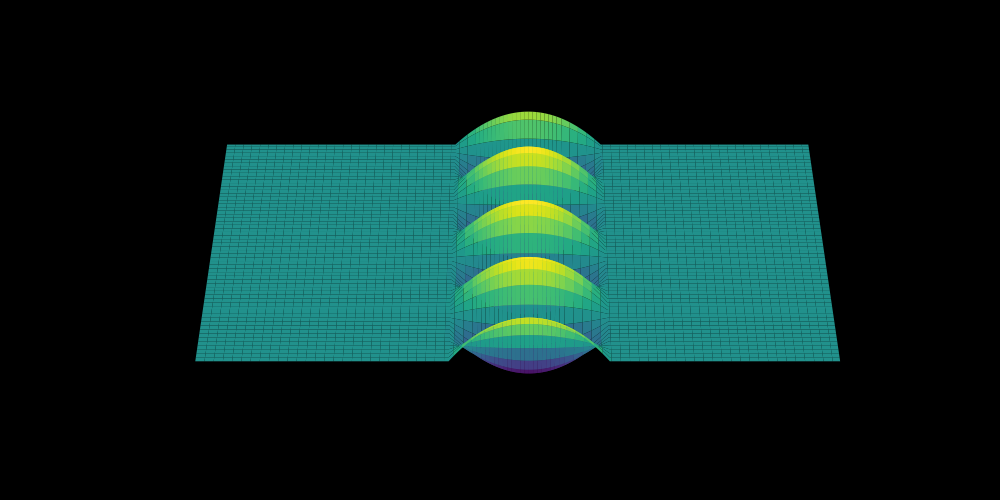

In [10]:
A.plot_field_2d_surface(F0);

## Guided modes

Energy propagated without loss in waveguides are carried in the device's guided modes. Therefor, to begin to determine the induced fields in the guide, we must calculate these guided modes.  We can visualize the locations of their propagation constants in the complex plane using the eigenvalue_plot method. 

In [11]:
A.eigenvalue_plot( -5, 5, -2.5, 3.5);

Guided modes have purely imaginary propagation constants.  It's clear that for the given guide there are two guided modes, one associated with each pure imaginary zero of the eigenvalue function.

To calculate them, we work manually or using built in methods.  If proceeding manually, we utilize scipy's newton solver along with initial guesses based on the plot:

In [12]:
guesses = [2.5j, 1.48j]
Zs = np.array([newton(A.eigenvalues, np.array(guess)) for guess in guesses])
A.plot_points(Zs)

Next we build the modes using the .fields method and visualize them.

In [13]:
Fs_guided = [A.fields(Z) for Z in Zs]

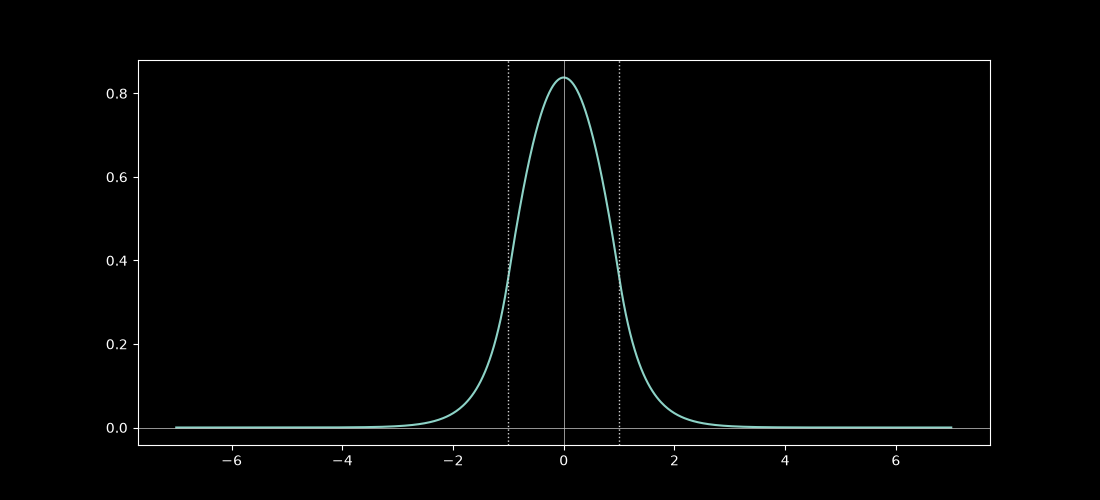

In [14]:
fig, ax = A.plot_field_1d(Fs_guided[0]);
fig.suptitle("Manually Calcuated Guided Modes")
for F in Fs_guided[1:]:
    A.add_1d_plot(F)


Using the built-in method one simply calls:

In [15]:
A.get_guided_modes()

This adds two list attributes to the Slab object: guided_modes and guided_mode_propagation_constants:

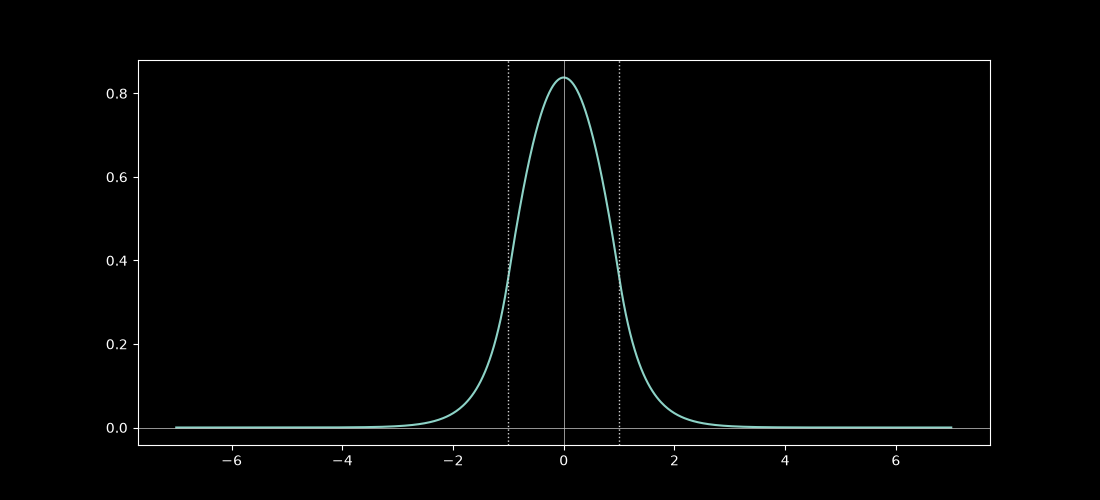

In [16]:
fig, ax = A.plot_field_1d(A.guided_modes[0]);
fig.suptitle("Automatically Calculated Guided Modes")
for F in A.guided_modes[1:]:
    A.add_1d_plot(F)


To determine the guided mode contribution to the full field, we find their weights by integrating them against the input field in the $x$-axis:

In [17]:
coeffs =  np.array([quad(lambda x: f0(x) * F(x, 0), Lx, Rx, complex_func=True)[0] for F in Fs_guided])

Note that these values are sufficient for finding the guided field, since, by default, the guided fields are normalized to already have square integral 1:

In [18]:
np.array([quad(lambda x: np.abs(F(x, 0))**2, A.Rhos[0], A.Rhos[-1], complex_func=True)[0] for F in Fs_guided])

array([1.        +0.j, 0.99999999+0.j])

We then build the guided field using these coefficients:

In [19]:
x0 = 0
z0 = 0
Guided = lambda x, z: sum([alpha * F(x, z) for (alpha, F) in zip(coeffs, Fs_guided)])

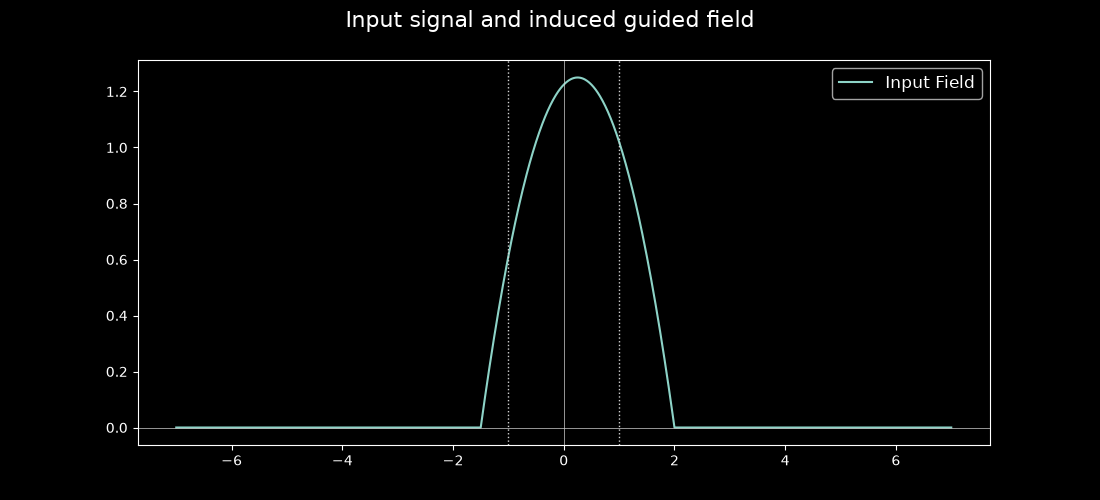

In [24]:
A.plot_field_1d(f0, label='Input Field', figsize=(11,5),
                figure_title="Input signal and induced guided field");
A.add_1d_plot(Guided, label='Guided Field');

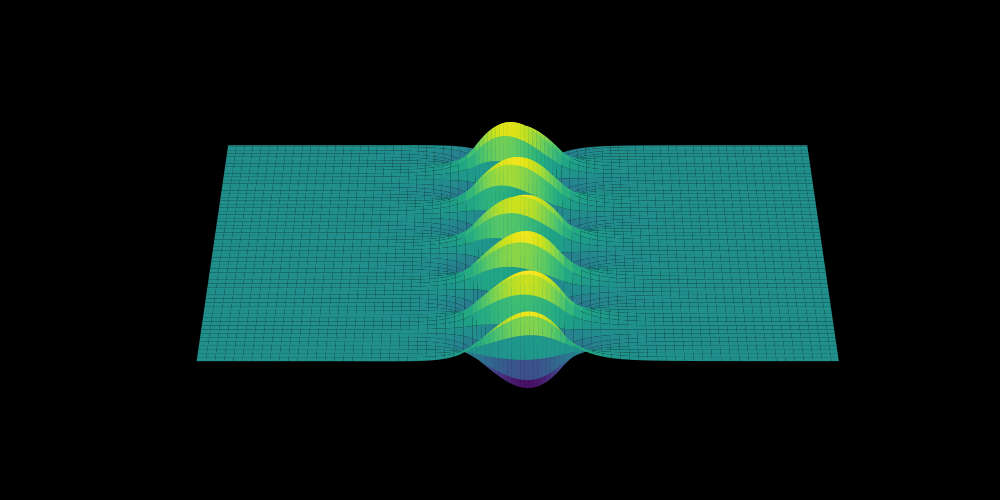

In [21]:
A.plot_field_2d_surface(Guided);


## Radiation Field

The remain portion of the field response is known as the radiation field, consisting of energy lost to free space.  To determine this part of the field, we calculate the radiation integral: an integral of weighted radiation modes over the positive real axis.

The Propagator class implements this. It begins by performing the radiation transform of the input field, which gives the necessary weights and then forming the full integral.

In [22]:
Propagator?

Init signature:
Propagator(
    Slab,
    f0=None,
    window=None,
    exact_transform=None,
    exact_kwargs={},
    field_type='TE',
    plane='Z',
    Normalization_Class=<class 'slabguide.normalizers.OurMethod'>,
    compute_class_I=True,
    compute_class_II=True,
    integration_args={},
    calculate_guided_field=True,
)
Docstring:      <no docstring>
Init docstring:
Class for computing induced fields in slab waveguides.

Given a guide "Slab" and either input field "f0" or "exact_transform",
an instance of this class enables computation of the resultant field in
the guide by forming the radiation integral over intervals of the real
line. It also allows for the extension of the radiation integral to
the complex plane, giving users the ability to verify the leaky mode
representation of the radiation field.

Instantiation requires either a single variable input field 'f0' and 
interval of transverse domain 'window' or exact_transform function.

Parameters
----------
Slab : Slab
  

In [23]:
P = Propagator(A, f0=f0, window=[Lx,Rx])

By default, the Propagator calculates the guided modes of the structure and the guided field induced by the input field.  Thus the work done above is completed on initiation of a propagator instance.  We can thus immediately plot the guided field by calling:

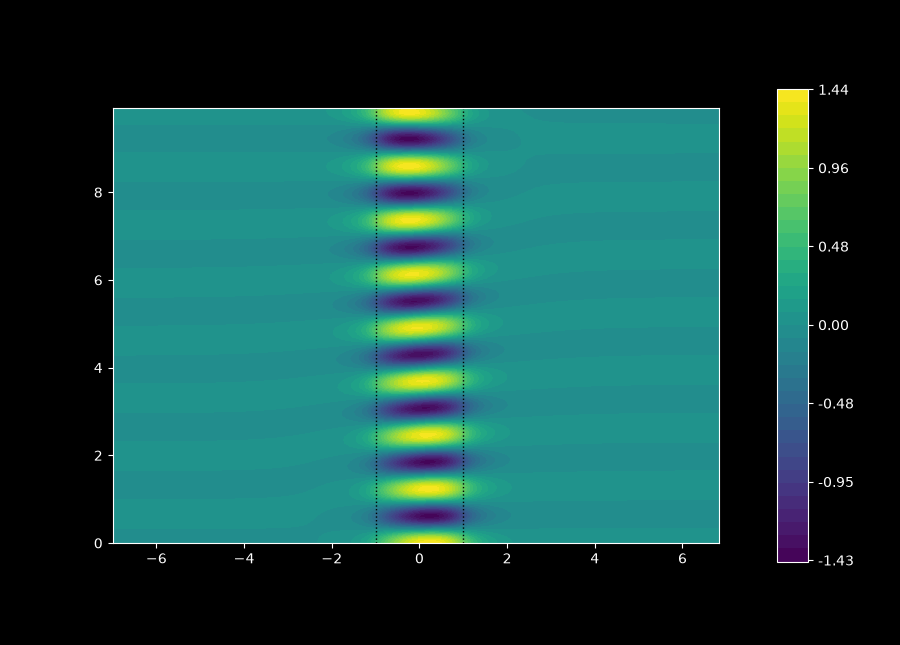

In [21]:
fig, ax = A.plot_field_2d(P.Guided);
# plt.show(fig);

Note that this behavior can be overidden by setting the keyword argumen calculate_guided_field to False in the constructor.  To find the radiation field, we add real valued contours to the propagator:

In [25]:
P.add_contour(real_contour(.00001, A.Z_evanescent, 150))

Adding the contour automatically calculates the values of the radiation transform along it.  These values can then be visualized by calling:

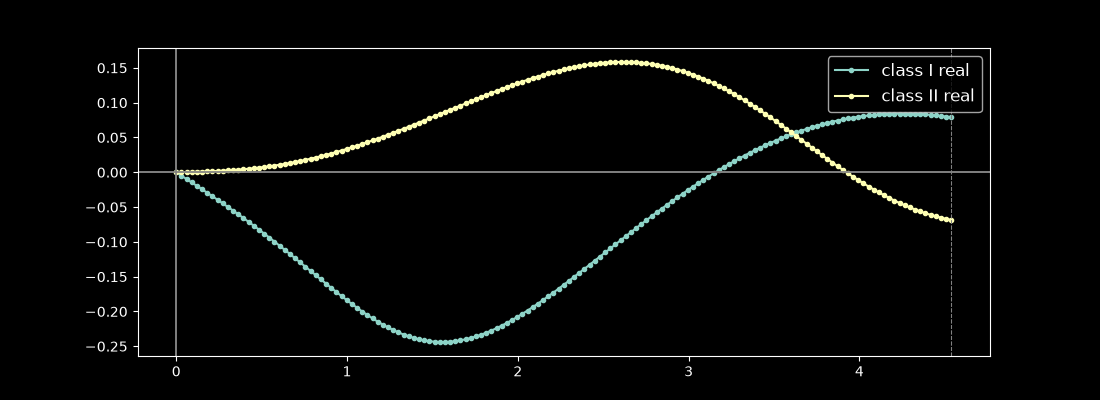

In [26]:
P.plot_transform();

To see how well we are approximating the input field as we integrate along the real line, we can plot the combined radiation and guided fields of the propagator.  This is as simple as calling:

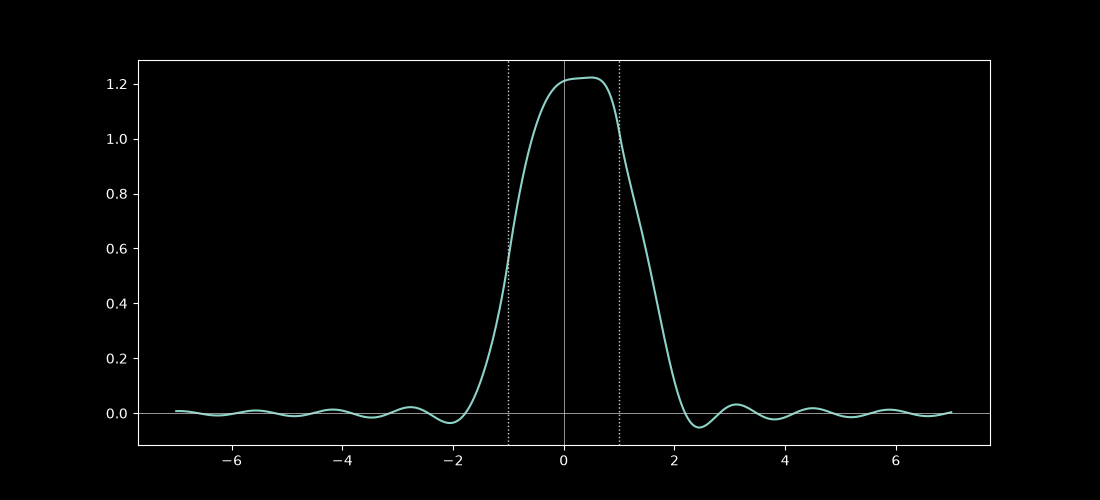

In [27]:
A.plot_field_1d(P)
A.add_1d_plot(f0)


We are already doing well. The resolve the remaining differences, we integrate further along the real line:

In [28]:
P.add_contour(real_contour(A.Z_evanescent, 8 * A.Z_evanescent, 200))

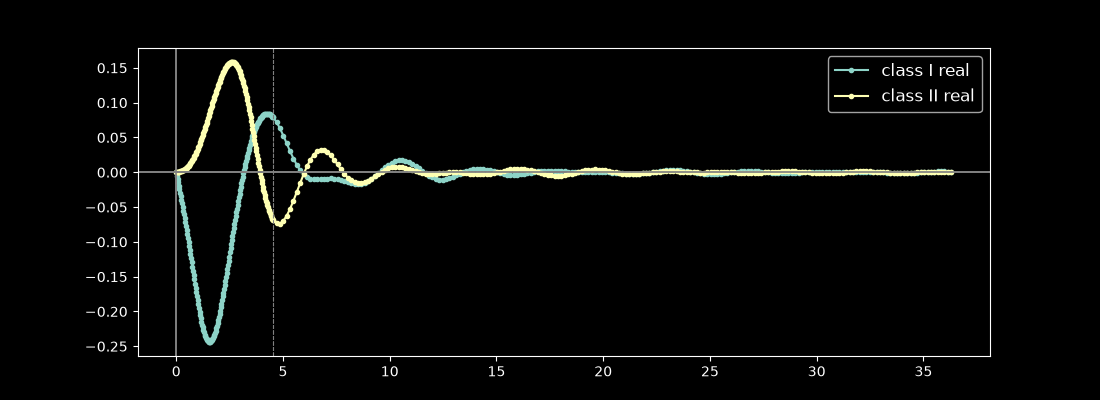

In [29]:
P.plot_transform();

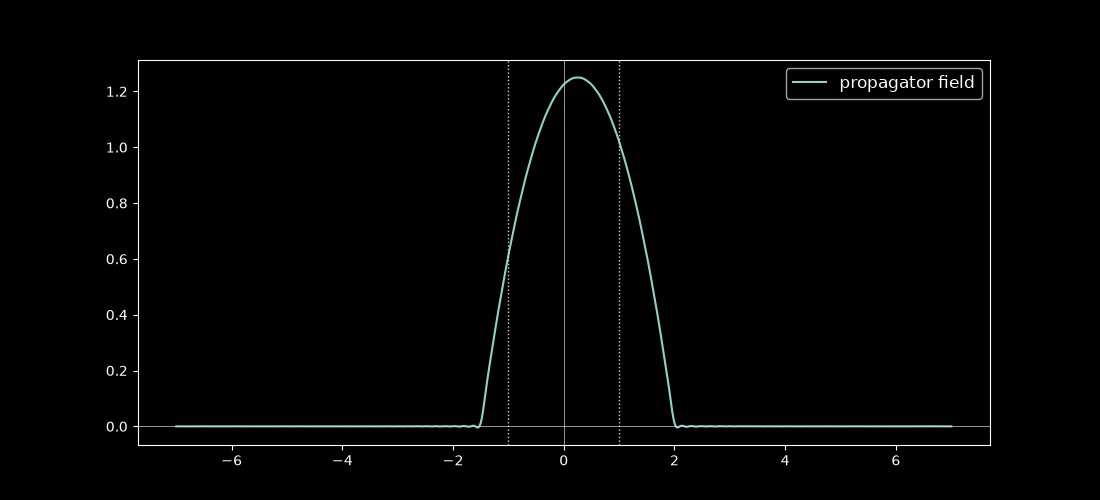

In [30]:
A.plot_field_1d(P, label='propagator field')
A.add_1d_plot(f0, ls='--', label='true input field')

Now that the propagator field matches the input field well at the endface of the guide, we can look at the full field in the guide:

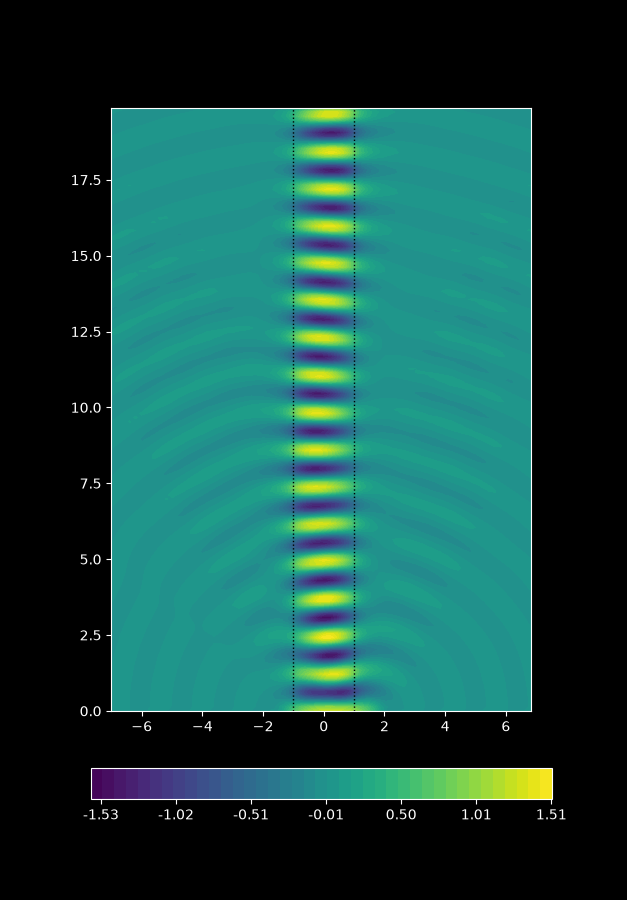

In [45]:
A.plot_field_2d(P, zmax=20);


## Plot3D

Using the Plot3D tool, we can visualize the induced fields in the guide in a streamlined interactive fashion:

In [37]:
Plot3D(P);


<slabguide.plotting.Plot3D.Plot3D.<locals>.HelloWidget object at 0x74d0b8065400>

## Visualizing Field Decompositions

We can view different components of the full field separately:

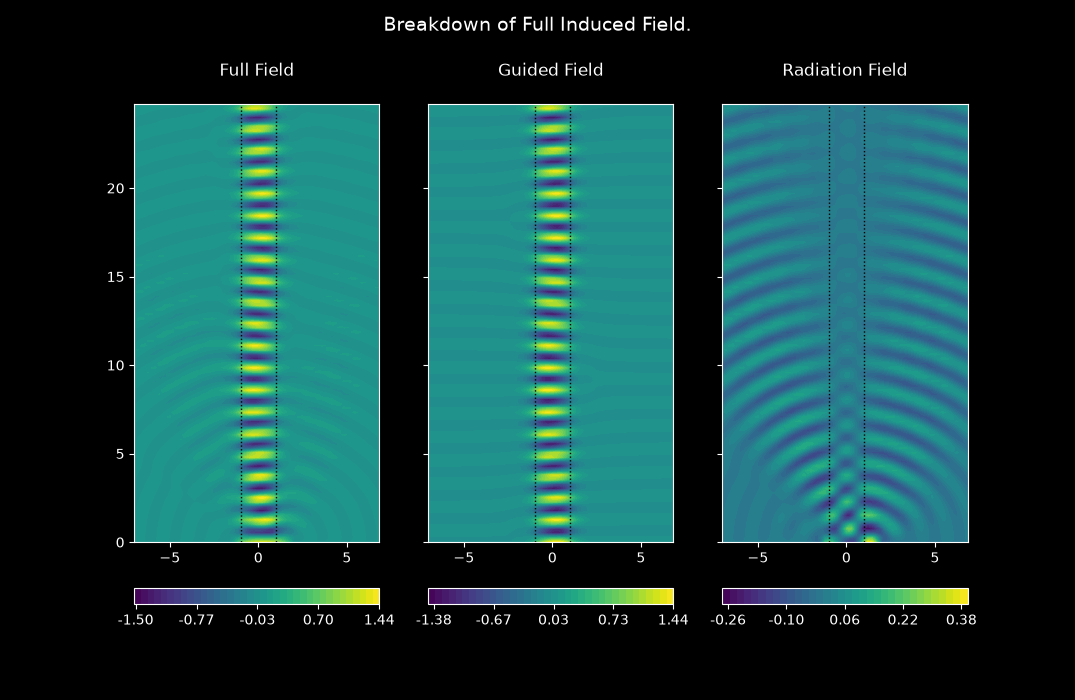

In [38]:
plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True, figsize=(10.75,7))
fig.suptitle('Breakdown of Full Induced Field.\n', fontsize=14)

A.add_2d_plot(P, ax=ax1, zmax=25, plot_Rhos=True, colorbar=True);
ax1.set_title('Full Field\n')
ax1.set_aspect('equal')

A.add_2d_plot(P.Guided, ax=ax2, zmax=25, plot_Rhos=True, colorbar=True);
ax2.set_title('Guided Field\n')
ax2.set_aspect('equal')

A.add_2d_plot(P.Radiation, ax=ax3, zmax=25, plot_Rhos=True, colorbar=True);
ax3.set_title('Radiation Field\n')
ax3.set_aspect('equal')
plt.show();

We can also view the breakdown of the radiation field into propagating and evanescent parts:

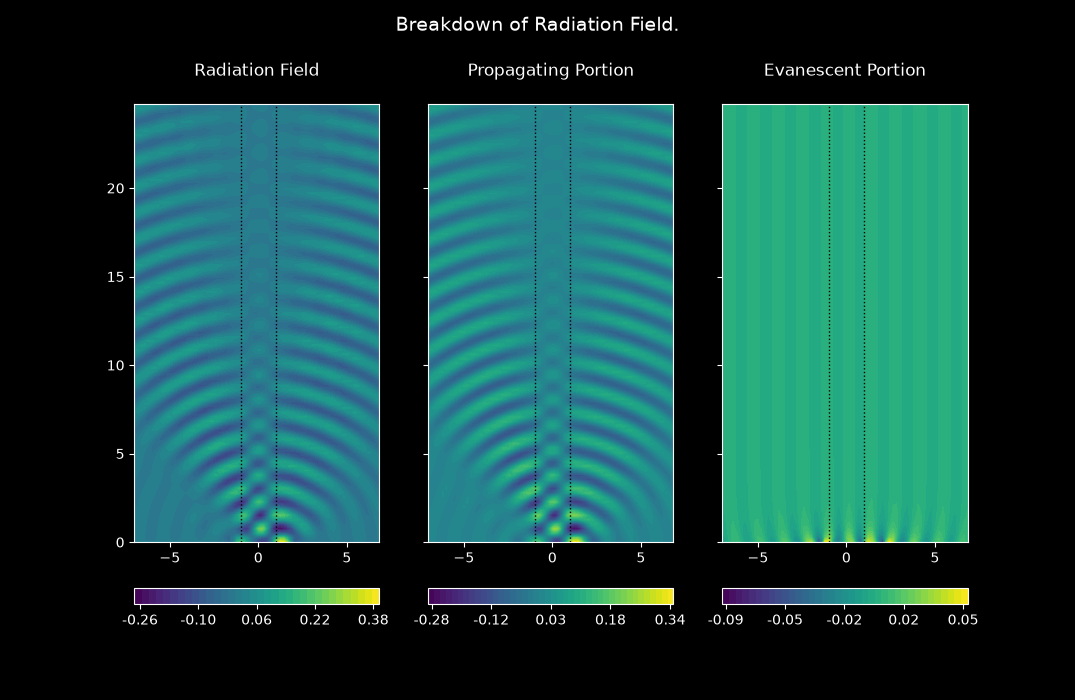

In [39]:
plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True, figsize=(10.75,7))
fig.suptitle('Breakdown of Radiation Field.\n', fontsize=14)

A.add_2d_plot(P.Radiation, ax=ax1, zmax=25, plot_Rhos=True, colorbar=True);
ax1.set_title('Radiation Field\n')
ax1.set_aspect('equal')

A.add_2d_plot(P.Propagating, ax=ax2, zmax=25, plot_Rhos=True, colorbar=True);
ax2.set_title('Propagating Portion\n')
ax2.set_aspect('equal')

A.add_2d_plot(P.Evanescent, ax=ax3, zmax=25, plot_Rhos=True, colorbar=True);
ax3.set_title('Evanescent Portion\n')
ax3.set_aspect('equal')
plt.show(fig);

Since the evanescent portion of the radiation field primarily contributes to refining detail at the input end of the device, the distinction is best visualized there:

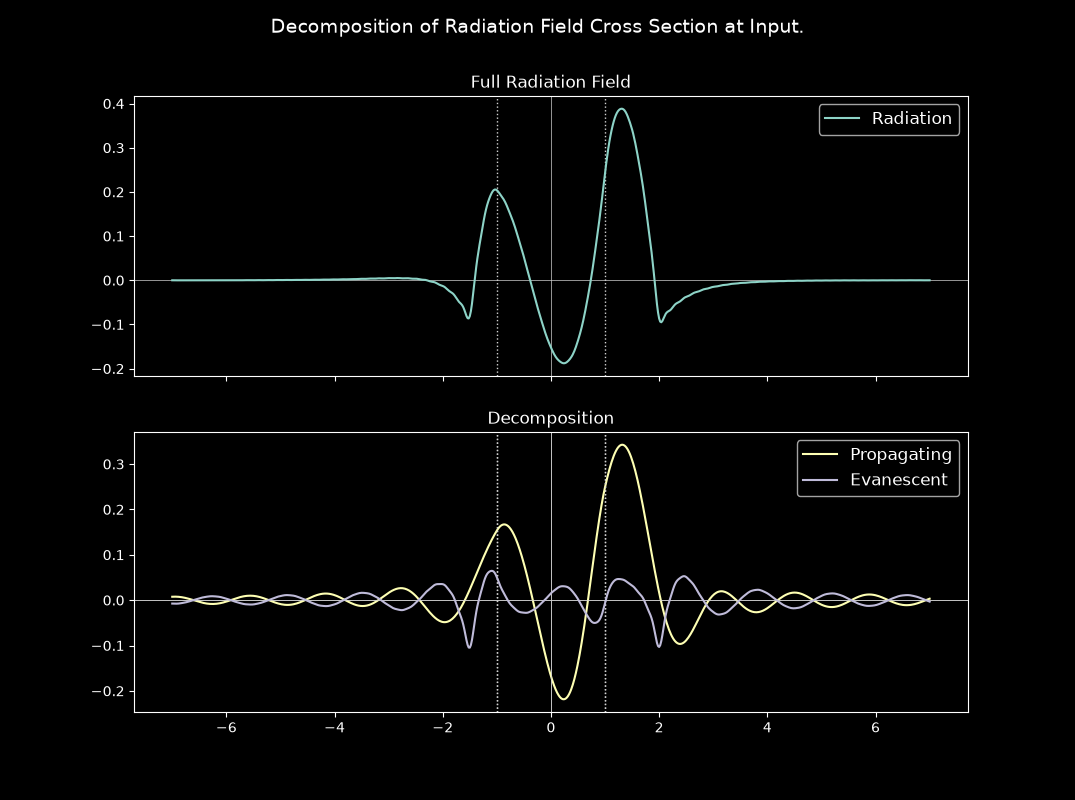

In [40]:
plt.close('all')
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10.75, 8))
fig.suptitle('Decomposition of Radiation Field Cross Section at Input.\n', fontsize=14);

A.add_1d_plot(P.Radiation, ax=ax1, c='C0', label='Radiation');
ax1.set_title('Full Radiation Field')

A.add_1d_plot(P.Propagating, ax=ax2, c='C1', label='Propagating');
A.add_1d_plot(P.Evanescent, ax=ax2, c='C2', label='Evanescent');
ax2.set_title('Decomposition');
plt.show(fig);

We can also view cross sections in the direction of propagation:

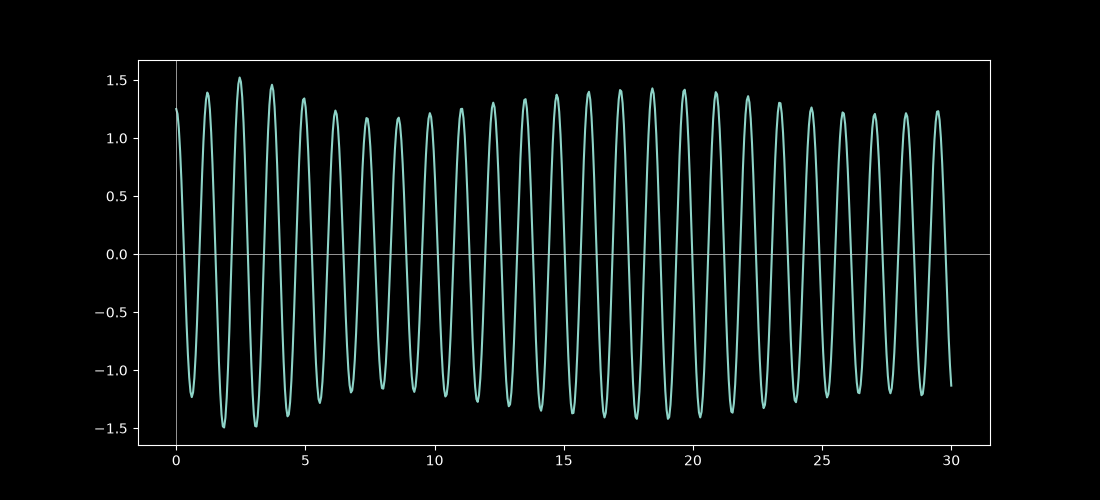

In [43]:
x0=shift
fig, ax = A.plot_field_1d(P, zs=np.linspace(0, 30, 600), xs=x0);

We can then see how propagation along the guided axis occurs in various parts of the field:

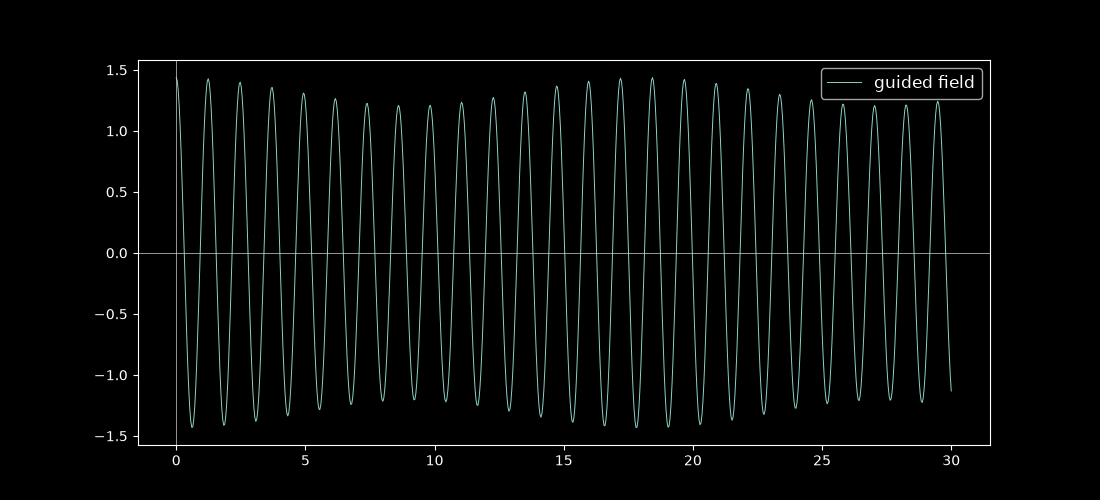

In [44]:
A.plot_field_1d(P.Guided, zs=np.linspace(0, 30, 800), xs=x0, lw=.7, label='guided field')
A.add_1d_plot(P.Radiation, zs=np.linspace(0, 30, 800), xs=x0, plot_Rhos=False, lw=.7, label='radiation field')

# Conclusion

This concludes the initial tutorial on the slab package.  Future topics include calculating leaky modes, extending the radiation integral to the complex plane, and asymptotic analysis of the radiation field via the method of steepest descent.

## Transverse axis Leaky vs True Rad

The correspondence is less good as a cross section in the $x$ axis:

In [ ]:
A.plot_field_1d(Rad, xs=np.linspace(-1, 1,1000), label='Radiation Field')
A.add_1d_plot(Leaky_w_Sdp, linestyle='--', xs=np.linspace(-1, 1,1000), label='Leaky Field + SDP')

This is due to the fact that many leaky modes are required to estimate the radiation field at the input end of the guide, but in this case very few are necessary to estimate the field in the direction of propagation.  This occurs because the leaky modes have very high loss, so only the first 2-3 have low enough loss to not almost immediatly exponentially decay to near zero in $z$, and hence play little role in $z$ behavior.  This isn't the case in the $x$ direction, where many must be chosen still.  

Note that for hollow core guides, with many low loss leaky modes, a great number of them must still be utilized to describe the true field in the direction of propagation.  Though this raises a question of whether this is true or if after Z_evansescent they still die off...

In [ ]:
Z_base = 1e-6
dZ = 1e-3 * Z_base
SpaceWave = A.space_wave_approx(f0, Z_base=Z_base, dZ=dZ, Lx=Lx, Rx=Rx)

In [ ]:
fig, ax = A.plot_field_1d(Sdp, zs=np.linspace(0, 20, 1000), xs=x0, label='SDP', lw=2.2);
A.add_1d_plot(SpaceWave, zs=np.linspace(.1, 20, 1000), xs=x0, label='Space Wave', lw=.8)
ax.set_ylim(-.3,.3);

In [ ]:
fig, ax = A.plot_field_1d(Sdp, zs=np.linspace(50, 100, 1000), xs=x0, label='SDP', lw=1.2);
A.add_1d_plot(SpaceWave, zs=np.linspace(50, 100, 1000), xs=x0, label='Space Wave', lw=.6)
ax.set_ylim(-.003,.003);

In [ ]:
fig, ax = A.plot_field_1d(Sdp, zs=np.linspace(150, 200, 1000), xs=x0, label='SDP', lw=1.2);
A.add_1d_plot(SpaceWave, zs=np.linspace(150, 200, 1000), xs=x0, label='Space Wave', lw=.6)
ax.set_ylim(-.001,.001);

In [ ]:
z0=1000
fig, ax = A.plot_field_1d(Sdp, zs=z0, label='SDP field');
A.add_1d_plot(SpaceWave, zs=z0, label='Asymptotic field', linestyle='--');
ax.set_title('Transverse Comparison of SDP and Asymptotic field at $z=%.2f$\n' %z0);